1 Event(s) in Catalog:
2026-09-27T18:55:43.715000Z | -43.086,  -72.623 | 4.4  mb | manual


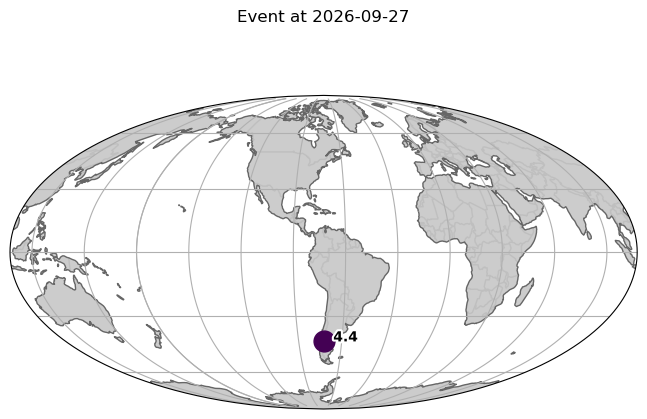

In [2]:
from obspy.clients.fdsn import Client
from obspy import UTCDateTime
client = Client("USGS") # USGS para obtener eventos a nivel mundial

ti = UTCDateTime("2026-09-27T18:55:00")
tf = UTCDateTime("2026-09-27T19:00:00")
catalogo = client.get_events(starttime=ti, endtime=tf, minmagnitude=4.0, minlatitude=-44, maxlatitude=-40, minlongitude=-75, maxlongitude=-70)

print(catalogo)

out = catalogo.plot()

**Lo marca como 4.4 mb (body-wave magnitude), declarado 4.6 Mw por el CSN**

**¿Qué mide mb?**
- Mide la amplitud de las ondas internas (P) en los primeros segundos del evento.

**¿Qué mide Mw (Magnitud de momento)?**
- El momento sísmico (área de ruptura, deslizamiento de la falla y rigidez de la roca).

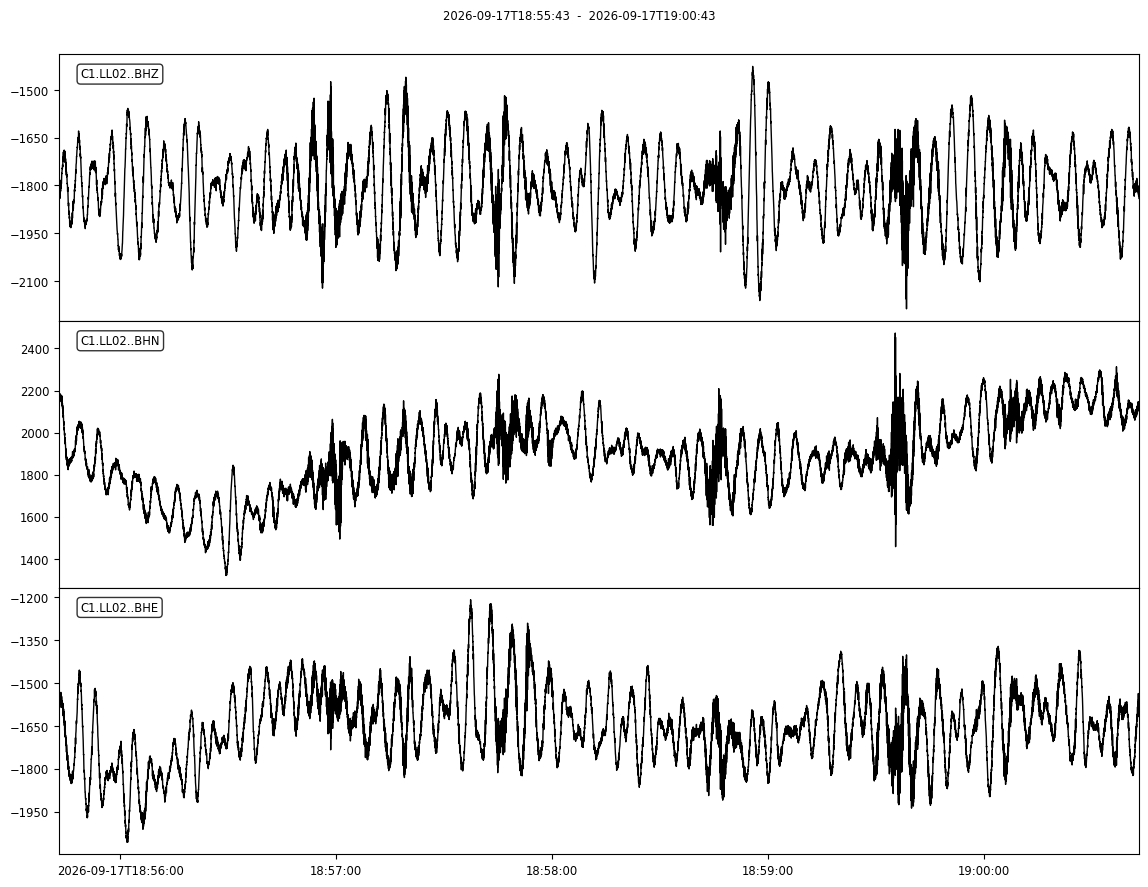

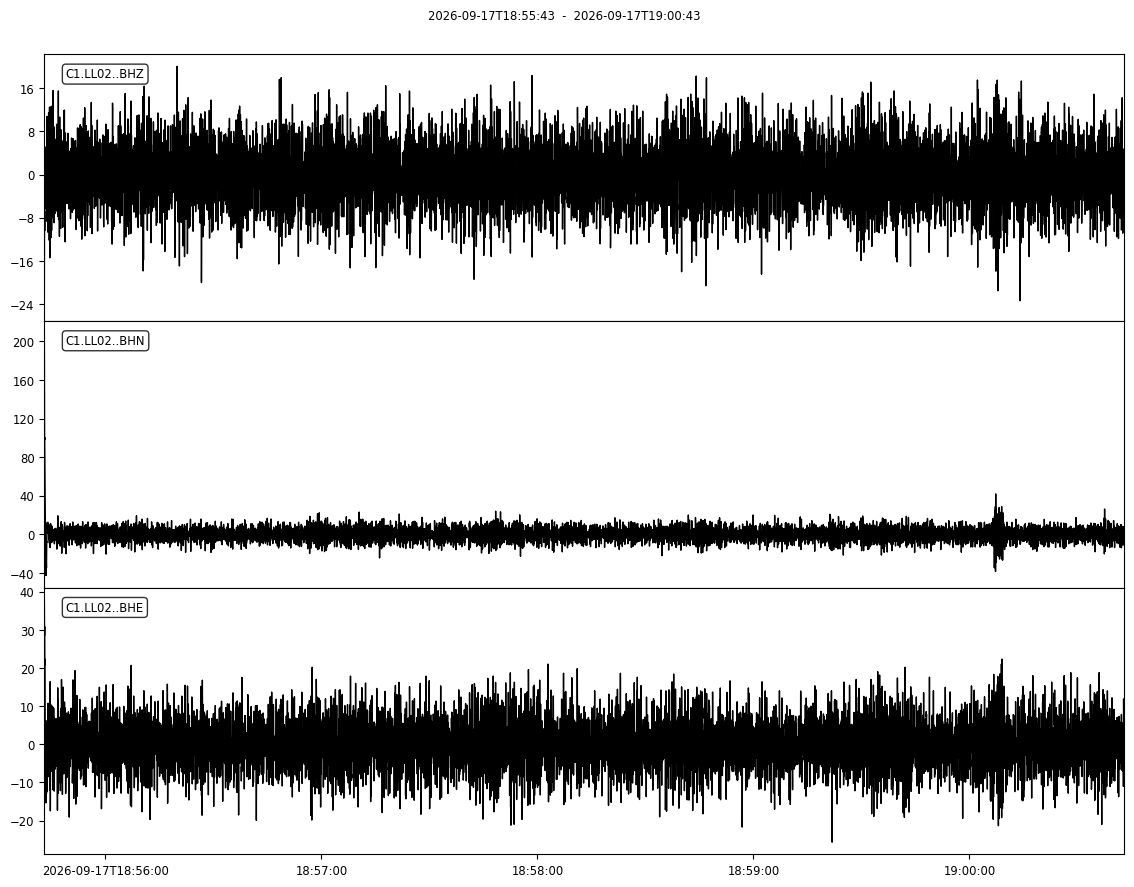

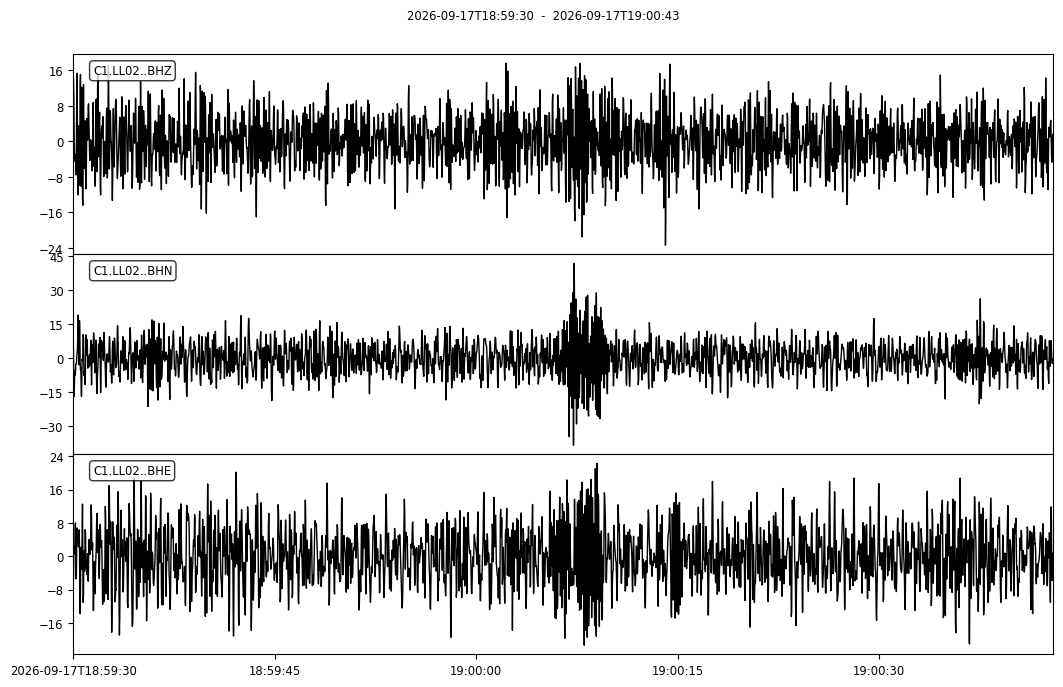

In [34]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy import Trace, UTCDateTime
import matplotlib.pyplot as plt
from obspy.io.sac.sacpz import attach_paz
client = Client("IRIS") # IRIS para obtener datos de estaciones sísmicas de todo el mundo

t = UTCDateTime("2026-09-17T18:55:43")

st = client.get_waveforms("C1", "LL02", "*", "BH?", t, t + 300)

f3 = st.plot(equal_scale=False, size=(1200, 900), number_of_ticks=5, show_y_UTC_label=True)

# 1. Copiar el Stream para preservar los datos crudos
st_filt = st.copy()

# 2. Retirar offset DC y tendencia lineal
st_filt.detrend(type="demean")
st_filt.detrend(type="linear")

# 3. Filtrar en la banda donde domina la energía de sismos locales (1 a 10 Hz)
st_filt.filter("bandpass", freqmin=1.0, freqmax=10.0, corners=4, zerophase=True)

# 4. Graficar para observar las fases limpias
fc = st_filt.plot(equal_scale=False, size=(1200, 900), number_of_ticks=5)

# Recortar ventana enfocada en el arribo detectado
t_zoom = UTCDateTime("2026-09-17T18:59:30")
st_zoom = st_filt.slice(starttime=t_zoom, endtime=t_zoom + 90)

# Graficar para análisis de fases P y S
sw = st_zoom.plot(equal_scale=False, size=(1100, 700))

In [ ]:
# Para verificar LR04:
# "https://service.earthscope.org/irisws/availability/1/query?net=C1&sta=LR04&cha=BHZ&format=geocsv&nodata=404"

Parámetros PAZ cargados:
AttribDict({'seismometer_gain': 1.0, 'digitizer_gain': 1.0, 'poles': [(-0.03852+0.03658j), (-0.03852-0.03658j), (-178+0j), (-135+160j), (-135-160j), (-671+1154j), (-671-1154j)], 'zeros': [0j, 0j, 0j, (-90+0j), (-160.7+0j), (-3108+0j)], 'sensitivity': 1.0, 'gain': 155150600000000.0})


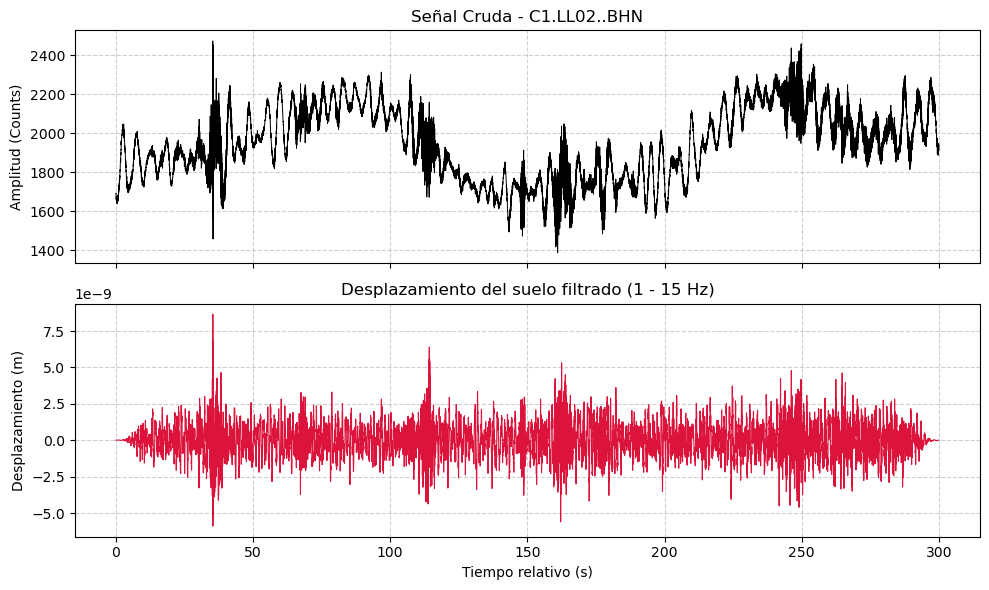

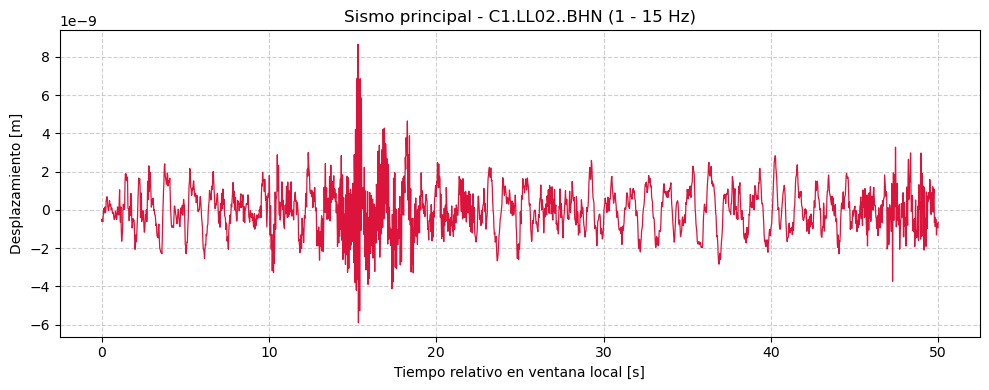

In [8]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy import Trace, UTCDateTime
import matplotlib.pyplot as plt
from obspy.io.sac.sacpz import attach_paz
client = Client("IRIS") # IRIS para obtener datos de estaciones sísmicas de todo el mundo

t = UTCDateTime("2026-09-17T18:59:00")

st = client.get_waveforms("C1", "LL02", "*", "BH?", t, t + 300)

# 2. Selección de la componente BHN y carga de SAC PZs
tr_n = st.select(channel="BHN")[0]
pz_file = "C1_LL02_BHN.PZs.txt"

attach_paz(tr_n, paz_file=pz_file)
paz = tr_n.stats.paz
print("Parámetros PAZ cargados:")
print(paz)

# 1. Copiar traza y acondicionar
tr_corregida = tr_n.copy()
tr_corregida.detrend(type="demean")
tr_corregida.detrend(type="linear")
tr_corregida.taper(max_percentage=0.05, type="cosine")

# 2. Pre-filtro ajustado para cortar el oleaje (elimina frecuencias < 0.5 - 1.0 Hz)
# f1, f2, f3, f4 en Hz
pre_filt = (0.5, 1.0, 15.0, 30.0)

# 3. Remover respuesta instrumental
tr_corregida.simulate(paz_remove=paz, pre_filt=pre_filt, water_level=60.0)

# 4. Graficar de nuevo
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
tt = tr_n.times(reftime=tr_n.stats.starttime)

ax1.plot(tt, tr_n.data, color='black', lw=0.7)
ax1.set_ylabel("Amplitud (Counts)")
ax1.set_title(f"Señal Cruda - {tr_n.id}")
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(tt, tr_corregida.data, color='crimson', lw=0.8)
ax2.set_ylabel("Desplazamiento (m)")
ax2.set_xlabel("Tiempo relativo (s)")
ax2.set_title("Desplazamiento del suelo filtrado (1 - 15 Hz)")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 1. Ventana de 50 segundos alrededor del primer evento (segundos 20 a 70)
t_primer_sismo = tr_corregida.stats.starttime + 20
tr_evento = tr_corregida.slice(starttime=t_primer_sismo, endtime=t_primer_sismo + 50)

# 2. Graficar forma de onda aislada
fig, ax = plt.subplots(figsize=(10, 4))
tt_ev = tr_evento.times(reftime=tr_evento.stats.starttime)

ax.plot(tt_ev, tr_evento.data, color="crimson", lw=0.9)
ax.set_ylabel("Desplazamiento [m]")
ax.set_xlabel("Tiempo relativo en ventana local [s]")
ax.set_title(f"Sismo principal - {tr_n.id} (1 - 15 Hz)")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()